# Set-up Colab

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os
import shutil
import zipfile

# Google Drive
DRIVE_ROOT = Path('/content/drive/MyDrive/NN')

# Arhive
PRE_ZIP = DRIVE_ROOT / 'pre-event.zip'
POST_ZIP = DRIVE_ROOT / 'post-event.zip'
TARGET_ZIP = DRIVE_ROOT / 'target.zip'

# Split-uri oficiale
SPLITS_DIR = DRIVE_ROOT / 'splits'

# Director local pentru dataset
DATASET_ROOT = Path('/content/BRIGHT')

OUTPUT_ROOT = DRIVE_ROOT / 'results_B'

print("Arhive existente:")
for p in [PRE_ZIP, POST_ZIP, TARGET_ZIP]:
    print(p.name, p.exists(),
          f"{p.stat().st_size / (1024**3):.2f} GB" if p.exists() else "")

print("\nSplit-uri:")
for p in SPLITS_DIR.glob('*.txt'):
    print(p.name, p.stat().st_size, "bytes")

print("\nSpațiu disponibil în Colab:")
total, used, free = shutil.disk_usage('/content')
print(f"{free / (1024**3):.2f} GB disponibili")

print("\nArhiva pre-event:")
with zipfile.ZipFile(PRE_ZIP) as z:
    print(*z.namelist()[:5], sep="\n")


Mounted at /content/drive
Arhive existente:
pre-event.zip True 9.22 GB
post-event.zip True 3.07 GB
target.zip True 0.04 GB

Split-uri:
test_set.txt 23040 bytes
train_set.txt 76672 bytes
val_set.txt 11785 bytes

Spațiu disponibil în Colab:
235.58 GB disponibili

Arhiva pre-event:
pre-event/
pre-event/turkey-earthquake_00000432_pre_disaster.tif
pre-event/bata-explosion_00000019_pre_disaster.tif
pre-event/ukraine-conflict_00000133_pre_disaster.tif
pre-event/turkey-earthquake_00000839_pre_disaster.tif


In [ ]:

import zipfile
from pathlib import Path
from collections import Counter

archives = {
    "pre-event": PRE_ZIP,
    "post-event": POST_ZIP,
    "target": TARGET_ZIP
}

for name, archive_path in archives.items():
    print(f"\n{'='*55}")
    print(f"ARCHIVE: {name}")
    print(f"{'='*55}")

    with zipfile.ZipFile(archive_path, 'r') as z:
        files = [f for f in z.namelist() if not f.endswith('/')]

        roots = Counter(
            f.split('/')[0] for f in files
        )

        print("Număr fișiere:", len(files))
        print("Foldere principale:", dict(roots))
        print("Dimensiune necomprimată:",
              round(sum(x.file_size for x in z.infolist()) / 1024**3, 2),
              "GB")

        print("\nPrimele 5 fișiere:")
        for f in files[:5]:
            print(" ", f)

# Verificăm și split-urile
print("\n" + "="*55)
print("OFFICIAL SPLITS")
print("="*55)

for split in ["train", "val", "test"]:
    path = SPLITS_DIR / f"{split}_set.txt"
    names = [x.strip() for x in path.read_text().splitlines() if x.strip()]
    print(f"{split}: {len(names)} samples")
    print("  Exemple:", names[:3])



ARCHIVE: pre-event
Număr fișiere: 4246
Foldere principale: {'pre-event': 4246}
Dimensiune necomprimată: 12.45 GB

Primele 5 fișiere:
  pre-event/turkey-earthquake_00000432_pre_disaster.tif
  pre-event/bata-explosion_00000019_pre_disaster.tif
  pre-event/ukraine-conflict_00000133_pre_disaster.tif
  pre-event/turkey-earthquake_00000839_pre_disaster.tif
  pre-event/turkey-earthquake_00000532_pre_disaster.tif

ARCHIVE: post-event
Număr fișiere: 4246
Foldere principale: {'post-event': 4246}
Dimensiune necomprimată: 4.17 GB

Primele 5 fișiere:
  post-event/libya-flood_00000007_post_disaster.tif
  post-event/noto-earthquake_00000032_post_disaster.tif
  post-event/turkey-earthquake_00000785_post_disaster.tif
  post-event/la_palma-volcano_00000870_post_disaster.tif
  post-event/libya-flood_00000045_post_disaster.tif

ARCHIVE: target
Număr fișiere: 4246
Foldere principale: {'target': 4246}
Dimensiune necomprimată: 4.15 GB

Primele 5 fișiere:
  target/morocco-earthquake_00000358_building_damage.

# Dataset and splits

In [ ]:

import zipfile
import shutil
from pathlib import Path
from tqdm.auto import tqdm

DATASET_ROOT = Path("/content/BRIGHT")
DATASET_ROOT.mkdir(parents=True, exist_ok=True)

archives = [
    (PRE_ZIP, "pre-event", 4246),
    (POST_ZIP, "post-event", 4246),
    (TARGET_ZIP, "target", 4246),
]

for archive_path, folder_name, expected_count in archives:
    output_folder = DATASET_ROOT / folder_name

    existing = list(output_folder.glob("*.tif")) if output_folder.exists() else []

    if len(existing) == expected_count:
        print(f"{folder_name}: deja extras ({len(existing)} fișiere).")
        continue

    print(f"\nExtragere {folder_name}...")

    with zipfile.ZipFile(archive_path, "r") as z:
        members = [
            m for m in z.infolist()
            if not m.is_dir()
        ]

        for member in tqdm(members, desc=folder_name):
            z.extract(member, DATASET_ROOT)

    actual = len(list(output_folder.glob("*.tif")))
    print(f"{folder_name}: {actual}/{expected_count} fișiere")

    assert actual == expected_count, (
        f"Număr incorect de fișiere în {folder_name}"
    )

print("\nExtragere finalizată!")
print("Dataset:", DATASET_ROOT)



Extragere pre-event...


pre-event:   0%|          | 0/4246 [00:00<?, ?it/s]

pre-event: 4246/4246 fișiere

Extragere post-event...


post-event:   0%|          | 0/4246 [00:00<?, ?it/s]

post-event: 4246/4246 fișiere

Extragere target...


target:   0%|          | 0/4246 [00:00<?, ?it/s]

target: 4246/4246 fișiere

Extragere finalizată!
Dataset: /content/BRIGHT


In [ ]:

# Citim identificatorii oficiali
split_names = {}

for split in ["train", "val", "test"]:
    path = SPLITS_DIR / f"{split}_set.txt"
    split_names[split] = {
        line.strip()
        for line in path.read_text().splitlines()
        if line.strip()
    }

# Identificăm toate fișierele după sufixele lor
pre_names = {
    p.name.removesuffix("_pre_disaster.tif")
    for p in (DATASET_ROOT / "pre-event").glob("*.tif")
}

post_names = {
    p.name.removesuffix("_post_disaster.tif")
    for p in (DATASET_ROOT / "post-event").glob("*.tif")
}

target_names = {
    p.name.removesuffix("_building_damage.tif")
    for p in (DATASET_ROOT / "target").glob("*.tif")
}

print("Verificare corespondență:")

assert pre_names == post_names, "Pre/post nu corespund!"
assert pre_names == target_names, "Pre/target nu corespund!"

all_names = set.union(*split_names.values())

assert all_names == pre_names, (
    f"Există diferențe: "
    f"lipsesc imagini={len(all_names - pre_names)}, "
    f"lipsesc din split={len(pre_names - all_names)}"
)

for split, names in split_names.items():
    print(f"{split}: {len(names)} exemple verificate")

print("\nSUCCESS: toate cele 4246 de exemple sunt asociate corect!")


Verificare corespondență:
train: 2918 exemple verificate
val: 450 exemple verificate
test: 878 exemple verificate

SUCCESS: toate cele 4246 de exemple sunt asociate corect!


In [ ]:

import imageio.v2 as imageio
import numpy as np
from pathlib import Path

# Luăm primul exemplu din train
sample_name = sorted(split_names["train"])[0]

pre_path = DATASET_ROOT / "pre-event" / f"{sample_name}_pre_disaster.tif"
post_path = DATASET_ROOT / "post-event" / f"{sample_name}_post_disaster.tif"
target_path = DATASET_ROOT / "target" / f"{sample_name}_building_damage.tif"

# Citim imaginile
optical = np.asarray(imageio.imread(pre_path))
sar = np.asarray(imageio.imread(post_path))
target = np.asarray(imageio.imread(target_path))

def inspect_image(name, img):
    print(f"\n{name}")
    print("-" * 40)
    print("Shape:", img.shape)
    print("Dtype:", img.dtype)
    print("Min:", img.min())
    print("Max:", img.max())
    print("Mean:", img.mean())
    print("Unique values:", np.unique(img)[:30])
    print("Number of unique values:", len(np.unique(img)))

print("Sample:", sample_name)

inspect_image("OPTICAL", optical)
inspect_image("SAR", sar)
inspect_image("TARGET", target)

# Verificări de compatibilitate
print("\n" + "=" * 45)
print("STRUCTURAL CHECKS")
print("=" * 45)

print("Optical RGB:", optical.ndim == 3 and optical.shape[-1] >= 3)
print("SAR single channel:", sar.ndim == 2 or
      (sar.ndim == 3 and sar.shape[-1] == 1))
print("Target grayscale:", target.ndim == 2)

print("Same spatial dimensions:",
      optical.shape[:2] == sar.shape[:2] == target.shape[:2])

print("Target classes:", np.unique(target))


Sample: bata-explosion_00000000

OPTICAL
----------------------------------------
Shape: (1024, 1024, 3)
Dtype: uint8
Min: 0
Max: 218
Mean: 18.199926376342773
Unique values: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29]
Number of unique values: 219

SAR
----------------------------------------
Shape: (1024, 1024)
Dtype: uint8
Min: 0
Max: 238
Mean: 8.181069374084473
Unique values: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29]
Number of unique values: 232

TARGET
----------------------------------------
Shape: (1024, 1024)
Dtype: uint8
Min: 0
Max: 1
Mean: 0.03780078887939453
Unique values: [0 1]
Number of unique values: 2

STRUCTURAL CHECKS
Optical RGB: True
SAR single channel: True
Target grayscale: True
Same spatial dimensions: True
Target classes: [0 1]


In [ ]:

import numpy as np
import imageio.v2 as imageio
from collections import Counter
import random

rng = random.Random(42)

sample_names = rng.sample(
    sorted(split_names["train"]),
    100
)

pixel_counts = Counter()
tiles_per_class = Counter()
unknown_values = Counter()

for name in sample_names:
    path = DATASET_ROOT / "target" / f"{name}_building_damage.tif"
    mask = np.asarray(imageio.imread(path))

    values, counts = np.unique(mask, return_counts=True)

    for value, count in zip(values, counts):
        pixel_counts[int(value)] += int(count)

    for value in values:
        tiles_per_class[int(value)] += 1

print("DISTRIBUTIA CLASELOR - 100 TRAIN TILES")
print("=" * 50)

total = sum(pixel_counts.values())

for cls in sorted(pixel_counts):
    count = pixel_counts[cls]
    print(
        f"Clasa {cls}: "
        f"{count:,} pixeli | "
        f"{100 * count / total:.4f}% | "
        f"prezentă în {tiles_per_class[cls]} tile-uri"
    )

print("\nValori întâlnite:", sorted(pixel_counts.keys()))

print("\nClasele așteptate: [0, 1, 2, 3]")
print("Clase lipsă:",
      sorted(set([0, 1, 2, 3]) - set(pixel_counts.keys())))


DISTRIBUTIA CLASELOR - 100 TRAIN TILES
Clasa 0: 91,726,895 pixeli | 87.4776% | prezentă în 100 tile-uri
Clasa 1: 10,950,566 pixeli | 10.4433% | prezentă în 72 tile-uri
Clasa 2: 1,929,147 pixeli | 1.8398% | prezentă în 22 tile-uri
Clasa 3: 250,992 pixeli | 0.2394% | prezentă în 17 tile-uri

Valori întâlnite: [0, 1, 2, 3]

Clasele așteptate: [0, 1, 2, 3]
Clase lipsă: []


In [ ]:

import numpy as np
import imageio.v2 as imageio
from tqdm.auto import tqdm
import json

# Statistics over the complete official training split
opt_sum = np.zeros(3, dtype=np.float64)
opt_sq_sum = np.zeros(3, dtype=np.float64)
opt_count = 0

sar_sum = 0.0
sar_sq_sum = 0.0
sar_count = 0

for name in tqdm(sorted(split_names["train"]),
                 desc="Full train normalization statistics"):

    pre_path = DATASET_ROOT / "pre-event" / f"{name}_pre_disaster.tif"
    post_path = DATASET_ROOT / "post-event" / f"{name}_post_disaster.tif"

    optical = np.asarray(
        imageio.imread(pre_path), dtype=np.float64
    )[..., :3]

    sar = np.asarray(
        imageio.imread(post_path), dtype=np.float64
    )

    # Optical RGB
    opt_sum += optical.sum(axis=(0, 1))
    opt_sq_sum += (optical ** 2).sum(axis=(0, 1))
    opt_count += optical.shape[0] * optical.shape[1]

    # SAR
    sar_sum += sar.sum()
    sar_sq_sum += (sar ** 2).sum()
    sar_count += sar.size

# Final statistics
opt_mean = opt_sum / opt_count
opt_std = np.sqrt(opt_sq_sum / opt_count - opt_mean ** 2)

sar_mean_full = sar_sum / sar_count
sar_std_full = np.sqrt(sar_sq_sum / sar_count - sar_mean_full ** 2)

stats = {
    "optical_mean": opt_mean.tolist(),
    "optical_std": opt_std.tolist(),
    "sar_mean": float(sar_mean_full),
    "sar_std": float(sar_std_full),
    "num_train_tiles": len(split_names["train"]),
    "include_zero_pixels": True
}

print("\nFINAL TRAIN STATISTICS")
print("=" * 50)
print("Optical mean:", stats["optical_mean"])
print("Optical std: ", stats["optical_std"])
print("SAR mean:    ", stats["sar_mean"])
print("SAR std:     ", stats["sar_std"])

# Save statistics in Google Drive
stats_path = OUTPUT_ROOT / "normalization_stats.json"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

with open(stats_path, "w") as f:
    json.dump(stats, f, indent=4)

print("\nSaved to:", stats_path)


Full train normalization statistics:   0%|          | 0/2918 [00:00<?, ?it/s]


FINAL TRAIN STATISTICS
Optical mean: [86.25556250415983, 83.14304792431628, 76.15842328748121]
Optical std:  [65.66245654487918, 57.34345847101453, 52.94283010149423]
SAR mean:     56.823117916350334
SAR std:      45.85530404183977

Saved to: /content/drive/MyDrive/NN/results_B/normalization_stats.json


In [ ]:
import json
from pathlib import Path

stats_path = OUTPUT_ROOT / "normalization_stats.json"

with open(stats_path, "r") as f:
    stats = json.load(f)

print("NORMALIZATION CONFIGURATION FOR MODEL B")
print("=" * 50)

print("[data.optical_norm]")
print(f"mean = {stats['optical_mean']}")
print(f"std = {stats['optical_std']}")

print("\n[data.sar_norm]")
print(f"mean = {stats['sar_mean']}")
print(f"std = {stats['sar_std']}")

print("\nNumber of training tiles:", stats["num_train_tiles"])

NORMALIZATION CONFIGURATION FOR MODEL B
[data.optical_norm]
mean = [86.25556250415983, 83.14304792431628, 76.15842328748121]
std = [65.66245654487918, 57.34345847101453, 52.94283010149423]

[data.sar_norm]
mean = 56.823117916350334
std = 45.85530404183977

Number of training tiles: 2918


In [ ]:
import json

stats_path = OUTPUT_ROOT / "normalization_stats.json"

with open(stats_path, "r") as f:
    norm_stats = json.load(f)

OPTICAL_MEAN = norm_stats["optical_mean"]
OPTICAL_STD = norm_stats["optical_std"]

SAR_MEAN = norm_stats["sar_mean"]
SAR_STD = norm_stats["sar_std"]

print("Optical mean:", OPTICAL_MEAN)
print("Optical std:", OPTICAL_STD)
print("SAR mean:", SAR_MEAN)
print("SAR std:", SAR_STD)

Optical mean: [86.25556250415983, 83.14304792431628, 76.15842328748121]
Optical std: [65.66245654487918, 57.34345847101453, 52.94283010149423]
SAR mean: 56.823117916350334
SAR std: 45.85530404183977


In [ ]:
import os
import random
import json
from pathlib import Path

import numpy as np
import imageio.v2 as imageio

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from tqdm.auto import tqdm
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [ ]:
from pathlib import Path

# Dataset
DATASET_ROOT = Path("/content/BRIGHT")

# Google Drive
DRIVE_ROOT = Path("/content/drive/MyDrive/NN")
SPLITS_DIR = DRIVE_ROOT / "splits"

# Output pentru modelul B
OUTPUT_ROOT = DRIVE_ROOT / "results_B"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# Split files
TRAIN_FILE = SPLITS_DIR / "train_set.txt"
VAL_FILE = SPLITS_DIR / "val_set.txt"
TEST_FILE = SPLITS_DIR / "test_set.txt"

# Verify paths
for path in [
    DATASET_ROOT / "pre-event",
    DATASET_ROOT / "post-event",
    DATASET_ROOT / "target",
    TRAIN_FILE,
    VAL_FILE,
    TEST_FILE
]:
    print(f"{path}: {'OK' if path.exists() else 'MISSING'}")

print("\nOutput directory:", OUTPUT_ROOT)

/content/BRIGHT/pre-event: OK
/content/BRIGHT/post-event: OK
/content/BRIGHT/target: OK
/content/drive/MyDrive/NN/splits/train_set.txt: OK
/content/drive/MyDrive/NN/splits/val_set.txt: OK
/content/drive/MyDrive/NN/splits/test_set.txt: OK

Output directory: /content/drive/MyDrive/NN/results_B


In [ ]:
def load_split(path):
    with open(path, "r") as f:
        return [line.strip() for line in f if line.strip()]


split_names = {
    "train": load_split(TRAIN_FILE),
    "val": load_split(VAL_FILE),
    "test": load_split(TEST_FILE)
}

for split, names in split_names.items():
    print(f"{split}: {len(names)} examples")

print("\nTotal:", sum(len(v) for v in split_names.values()))

train: 2918 examples
val: 450 examples
test: 878 examples

Total: 4246


# Data Preprocessing

In [ ]:
import random
import numpy as np
import imageio.v2 as imageio
import torch
from torch.utils.data import Dataset, DataLoader

# Normalization statistics
OPTICAL_MEAN = np.array([
    86.25556250415983,
    83.14304792431628,
    76.15842328748121
], dtype=np.float32)

OPTICAL_STD = np.array([
    65.66245654487918,
    57.34345847101453,
    52.94283010149423
], dtype=np.float32)

SAR_MEAN = 56.823117916350334
SAR_STD = 45.85530404183977

IGNORE_INDEX = 255
CROP_SIZE = 512


class BrightDataset(Dataset):

    def __init__(self, names, dataset_root, augment=False):
        self.names = names
        self.root = Path(dataset_root)
        self.augment = augment

    def __len__(self):
        return len(self.names)

    def __getitem__(self, index):

        name = self.names[index]

        # Load images
        optical = imageio.imread(
            self.root / "pre-event" /
            f"{name}_pre_disaster.tif"
        )[..., :3].astype(np.float32)

        sar = imageio.imread(
            self.root / "post-event" /
            f"{name}_post_disaster.tif"
        ).astype(np.float32)

        target = imageio.imread(
            self.root / "target" /
            f"{name}_building_damage.tif"
        ).astype(np.int64)

        if sar.ndim == 2:
            sar = sar[..., None]

        # Synchronized augmentations
        if self.augment:

            h, w = target.shape

            # Random crop
            top = random.randint(0, h - CROP_SIZE)
            left = random.randint(0, w - CROP_SIZE)

            optical = optical[
                top:top+CROP_SIZE, left:left+CROP_SIZE
            ]
            sar = sar[
                top:top+CROP_SIZE, left:left+CROP_SIZE
            ]
            target = target[
                top:top+CROP_SIZE, left:left+CROP_SIZE
            ]

            # Horizontal flip
            if random.random() < 0.5:
                optical = np.fliplr(optical)
                sar = np.fliplr(sar)
                target = np.fliplr(target)

            # Vertical flip
            if random.random() < 0.5:
                optical = np.flipud(optical)
                sar = np.flipud(sar)
                target = np.flipud(target)

            # Random rotation: 90, 180 or 270 degrees
            k = random.randint(1, 3)
            optical = np.rot90(optical, k)
            sar = np.rot90(sar, k)
            target = np.rot90(target, k)

        # Normalize
        optical = (optical - OPTICAL_MEAN) / OPTICAL_STD
        sar = (sar - SAR_MEAN) / SAR_STD

        # HWC -> CHW
        optical = torch.from_numpy(
            np.ascontiguousarray(optical.transpose(2, 0, 1))
        ).float()

        sar = torch.from_numpy(
            np.ascontiguousarray(sar.transpose(2, 0, 1))
        ).float()

        target = torch.from_numpy(
            np.ascontiguousarray(target)
        ).long()

        return optical, sar, target, name

In [ ]:
# Create a small test dataset
train_dataset = BrightDataset(
    names=split_names["train"],
    dataset_root=DATASET_ROOT,
    augment=True
)

# Load one sample
optical, sar, target, name = train_dataset[0]

print("Sample:", name)
print("-" * 45)

print("Optical shape:", optical.shape)
print("SAR shape:", sar.shape)
print("Target shape:", target.shape)

print("\nOptical dtype:", optical.dtype)
print("SAR dtype:", sar.dtype)
print("Target dtype:", target.dtype)

print("\nOptical range:", optical.min().item(), optical.max().item())
print("SAR range:", sar.min().item(), sar.max().item())
print("Target classes:", torch.unique(target).tolist())

Sample: bata-explosion_00000014
---------------------------------------------
Optical shape: torch.Size([3, 512, 512])
SAR shape: torch.Size([1, 512, 512])
Target shape: torch.Size([512, 512])

Optical dtype: torch.float32
SAR dtype: torch.float32
Target dtype: torch.int64

Optical range: -1.4385031461715698 2.962470769882202
SAR range: -1.2391830682754517 3.8856329917907715
Target classes: [0, 1]


In [ ]:
# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# DataLoaders
BATCH_SIZE = 16
NUM_WORKERS = 4

train_dataset = BrightDataset(
    split_names["train"],
    DATASET_ROOT,
    augment=True
)

val_dataset = BrightDataset(
    split_names["val"],
    DATASET_ROOT,
    augment=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 182
Validation batches: 450


In [ ]:
optical, sar, target, names = next(iter(train_loader))

print("Optical batch:", optical.shape)
print("SAR batch:", sar.shape)
print("Target batch:", target.shape)
print("Target classes:", torch.unique(target).tolist())

Optical batch: torch.Size([16, 3, 512, 512])
SAR batch: torch.Size([16, 1, 512, 512])
Target batch: torch.Size([16, 512, 512])
Target classes: [0, 1, 2, 3]


# Model B - 2 encoders U-Net, feature level concat

In [ ]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class Encoder(nn.Module):
    def __init__(self, in_channels):
        super().__init__()

        channels = [32, 64, 128, 256, 512]

        self.blocks = nn.ModuleList()
        self.pool = nn.MaxPool2d(2)

        previous = in_channels

        for channel in channels:
            self.blocks.append(
                ConvBlock(previous, channel)
            )
            previous = channel

    def forward(self, x):
        features = []

        for i, block in enumerate(self.blocks):
            x = block(x)
            features.append(x)

            if i < len(self.blocks) - 1:
                x = self.pool(x)

        return features


print("ConvBlock and Encoder defined successfully!")

ConvBlock and Encoder defined successfully!


In [ ]:
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()

        self.up = nn.ConvTranspose2d(
            in_channels, out_channels,
            kernel_size=2, stride=2
        )

        self.conv = ConvBlock(
            out_channels + skip_channels,
            out_channels
        )

    def forward(self, x, skip):
        x = self.up(x)

        # Safety in case spatial dimensions differ
        if x.shape[2:] != skip.shape[2:]:
            x = F.interpolate(
                x,
                size=skip.shape[2:],
                mode="bilinear",
                align_corners=False
            )

        x = torch.cat([x, skip], dim=1)
        return self.conv(x)


class FusionDecoder(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        # Each encoder has channels [32, 64, 128, 256, 512]
        # Concatenated features: [64, 128, 256, 512, 1024]

        self.decoder4 = DecoderBlock(1024, 512, 256)
        self.decoder3 = DecoderBlock(256, 256, 128)
        self.decoder2 = DecoderBlock(128, 128, 64)
        self.decoder1 = DecoderBlock(64, 64, 32)

        self.classifier = nn.Conv2d(
            32, num_classes, kernel_size=1
        )

    def forward(self, fused_features):

        x = fused_features[4]

        x = self.decoder4(x, fused_features[3])
        x = self.decoder3(x, fused_features[2])
        x = self.decoder2(x, fused_features[1])
        x = self.decoder1(x, fused_features[0])

        return self.classifier(x)


print("Decoder and fusion components defined successfully!")

Decoder and fusion components defined successfully!


In [ ]:
class TwoStreamFusionNet(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        # Separate encoders
        self.optical_encoder = Encoder(in_channels=3)
        self.sar_encoder = Encoder(in_channels=1)

        # Feature-level fusion
        self.decoder = FusionDecoder(num_classes=num_classes)

    def forward(self, optical, sar):

        # Extract features independently
        optical_features = self.optical_encoder(optical)
        sar_features = self.sar_encoder(sar)

        # Concatenate features at each resolution
        fused_features = []

        for optical_feat, sar_feat in zip(
            optical_features, sar_features
        ):
            fused = torch.cat(
                [optical_feat, sar_feat],
                dim=1
            )
            fused_features.append(fused)

        # Decode fused features
        output = self.decoder(fused_features)

        return output


print("TwoStreamFusionNet defined successfully!")

TwoStreamFusionNet defined successfully!


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = TwoStreamFusionNet(num_classes=4).to(device)

# Test with one batch
optical_test = optical[:2].to(device)
sar_test = sar[:2].to(device)

model.eval()

with torch.no_grad():
    output = model(optical_test, sar_test)

print("Optical input:", optical_test.shape)
print("SAR input:", sar_test.shape)
print("Model output:", output.shape)

print(
    "Total parameters:",
    f"{sum(p.numel() for p in model.parameters()):,}"
)

Optical input: torch.Size([2, 3, 512, 512])
SAR input: torch.Size([2, 1, 512, 512])
Model output: torch.Size([2, 4, 512, 512])
Total parameters: 13,784,420


In [ ]:
def lovasz_grad(gt_sorted):
    """
    Computes gradient of the Lovasz extension.
    """
    p = len(gt_sorted)
    gts = gt_sorted.sum()

    intersection = gts - gt_sorted.float().cumsum(0)
    union = gts + (1 - gt_sorted.float()).cumsum(0)

    jaccard = 1.0 - intersection / union

    if p > 1:
        jaccard = torch.cat([
            jaccard[:1],
            jaccard[1:] - jaccard[:-1]
        ])

    return jaccard


def lovasz_softmax_flat(probas, labels, classes="present"):
    """
    Multi-class Lovasz-Softmax loss.
    probas: [P, C]
    labels: [P]
    """
    C = probas.shape[1]
    losses = []

    class_to_sum = (
        range(C) if classes in ["all", "present"] else classes
    )

    for c in class_to_sum:
        fg = (labels == c).float()

        if classes == "present" and fg.sum() == 0:
            continue

        if fg.sum() == 0:
            continue

        errors = (fg - probas[:, c]).abs()

        errors_sorted, perm = torch.sort(
            errors, descending=True
        )

        fg_sorted = fg[perm]

        grad = lovasz_grad(fg_sorted)

        losses.append(torch.dot(errors_sorted, grad))

    if len(losses) == 0:
        return probas.sum() * 0.0

    return torch.stack(losses).mean()


def lovasz_softmax(
    logits,
    labels,
    ignore_index=255
):
    """
    logits: [B, C, H, W]
    labels: [B, H, W]
    """
    probs = F.softmax(logits, dim=1)

    losses = []

    for prob, label in zip(probs, labels):

        valid = label != ignore_index

        prob = prob.permute(1, 2, 0).reshape(-1, prob.shape[0])
        label = label.reshape(-1)

        prob = prob[valid.reshape(-1)]
        label = label[valid.reshape(-1)]

        if label.numel() == 0:
            continue

        losses.append(
            lovasz_softmax_flat(prob, label, classes="present")
        )

    if len(losses) == 0:
        return logits.sum() * 0.0

    return torch.stack(losses).mean()


class CombinedLoss(nn.Module):
    def __init__(
        self,
        lovasz_weight=0.75,
        ignore_index=255
    ):
        super().__init__()

        self.lovasz_weight = lovasz_weight
        self.ce = nn.CrossEntropyLoss(
            ignore_index=ignore_index
        )

    def forward(self, logits, target):

        ce_loss = self.ce(logits, target)

        lovasz_loss = lovasz_softmax(
            logits,
            target,
            ignore_index=255
        )

        total_loss = (
            ce_loss +
            self.lovasz_weight * lovasz_loss
        )

        return total_loss, ce_loss, lovasz_loss


print("Combined CE + Lovasz-Softmax loss defined successfully!")

Combined CE + Lovasz-Softmax loss defined successfully!


In [ ]:
criterion = CombinedLoss(
    lovasz_weight=0.75,
    ignore_index=255
).to(device)

model.train()

optical_batch = optical[:2].to(device)
sar_batch = sar[:2].to(device)
target_batch = target[:2].to(device)

logits = model(optical_batch, sar_batch)

loss, ce_loss, lovasz_loss = criterion(
    logits,
    target_batch
)

print("Total loss:", loss.item())
print("Cross Entropy:", ce_loss.item())
print("Lovasz-Softmax:", lovasz_loss.item())

loss.backward()

print(
    "Gradient test:",
    "SUCCESS" if model.optical_encoder.blocks[0].block[0].weight.grad is not None
    else "FAILED"
)

model.zero_grad(set_to_none=True)

Total loss: 1.8971035480499268
Cross Entropy: 1.3567917346954346
Lovasz-Softmax: 0.7204157114028931
Gradient test: SUCCESS


In [ ]:
# Training configuration

EPOCHS = 50
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 5e-3
LOVASZ_WEIGHT = 0.75

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

criterion = CombinedLoss(
    lovasz_weight=LOVASZ_WEIGHT,
    ignore_index=IGNORE_INDEX
).to(device)

print("Optimizer:", type(optimizer).__name__)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Device:", device)

Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.005
Epochs: 50
Batch size: 16
Device: cuda


In [ ]:
torch.cuda.empty_cache()

print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

print(
    "GPU memory reserved:",
    round(torch.cuda.memory_reserved() / 1024**3, 2),
    "GB"
)

print(
    "GPU total memory:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "GB"
)

GPU memory allocated: 2.14 GB
GPU memory reserved: 2.51 GB
GPU total memory: 94.97 GB


In [ ]:
import numpy as np
import torch

NUM_CLASSES = 4
CLASS_NAMES = ["Background", "Intact", "Damaged", "Destroyed"]


class SegmentationMetrics:
    def __init__(self, num_classes=4, ignore_index=255):
        self.num_classes = num_classes
        self.ignore_index = ignore_index
        self.confusion_matrix = np.zeros(
            (num_classes, num_classes), dtype=np.int64
        )

    def update(self, logits, target):
        predictions = logits.argmax(dim=1)

        predictions = predictions.detach().cpu().numpy().reshape(-1)
        target = target.detach().cpu().numpy().reshape(-1)

        valid = (
            (target != self.ignore_index) &
            (target >= 0) &
            (target < self.num_classes)
        )

        target = target[valid]
        predictions = predictions[valid]

        indices = target * self.num_classes + predictions

        self.confusion_matrix += np.bincount(
            indices,
            minlength=self.num_classes ** 2
        ).reshape(self.num_classes, self.num_classes)

    def compute(self):
        cm = self.confusion_matrix

        true_positive = np.diag(cm)
        actual = cm.sum(axis=1)
        predicted = cm.sum(axis=0)

        union = actual + predicted - true_positive

        iou = np.divide(
            true_positive,
            union,
            out=np.full(self.num_classes, np.nan),
            where=union != 0
        )

        f1 = np.divide(
            2 * true_positive,
            actual + predicted,
            out=np.full(self.num_classes, np.nan),
            where=(actual + predicted) != 0
        )

        total = cm.sum()
        oa = true_positive.sum() / total if total > 0 else 0.0

        return {
            "iou_per_class": iou,
            "f1_per_class": f1,
            "miou": float(np.nanmean(iou)),
            "oa": float(oa),
            "confusion_matrix": cm.copy()
        }


print("Segmentation metrics defined successfully!")

Segmentation metrics defined successfully!


In [ ]:
@torch.no_grad()
def evaluate_model(model, loader, criterion, device):

    model.eval()

    metrics = SegmentationMetrics(
        num_classes=NUM_CLASSES,
        ignore_index=IGNORE_INDEX
    )

    total_loss = 0.0
    total_ce = 0.0
    total_lovasz = 0.0

    for optical, sar, target, names in tqdm(
        loader, desc="Validation", leave=False
    ):

        optical = optical.to(device, non_blocking=True)
        sar = sar.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)

        logits = model(optical, sar)

        loss, ce_loss, lovasz_loss = criterion(logits, target)

        total_loss += loss.item()
        total_ce += ce_loss.item()
        total_lovasz += lovasz_loss.item()

        metrics.update(logits, target)

    results = metrics.compute()

    num_batches = len(loader)

    results["loss"] = total_loss / num_batches
    results["ce_loss"] = total_ce / num_batches
    results["lovasz_loss"] = total_lovasz / num_batches

    return results


print("Evaluation function defined successfully!")

Evaluation function defined successfully!


In [ ]:
initial_results = evaluate_model(
    model=model,
    loader=val_loader,
    criterion=criterion,
    device=device
)

print("\nINITIAL VALIDATION RESULTS")
print("=" * 50)

print(f"Loss: {initial_results['loss']:.4f}")
print(f"mIoU: {initial_results['miou']:.4f}")
print(f"OA:   {initial_results['oa']:.4f}")

print("\nPer-class metrics:")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:12s} | "
        f"IoU: {initial_results['iou_per_class'][i]:.4f} | "
        f"F1: {initial_results['f1_per_class'][i]:.4f}"
    )

Validation:   0%|          | 0/450 [00:00<?, ?it/s]


INITIAL VALIDATION RESULTS
Loss: 1.9000
mIoU: 0.0294
OA:   0.1177

Per-class metrics:
Background   | IoU: 0.0000 | F1: 0.0000
Intact       | IoU: 0.1177 | F1: 0.2106
Damaged      | IoU: 0.0000 | F1: 0.0000
Destroyed    | IoU: 0.0000 | F1: 0.0000


In [ ]:
# Reinitialize model from scratch
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)
np.random.seed(42)
random.seed(42)

model = TwoStreamFusionNet(num_classes=4).to(device)

criterion = CombinedLoss(
    lovasz_weight=0.75,
    ignore_index=255
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=5e-3
)

EPOCHS = 50
best_miou = -1.0

print("Model reinitialized successfully!")
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Optimizer: AdamW")
print("Learning rate:", 1e-4)
print("Weight decay:", 5e-3)
print("Epochs:", EPOCHS)

Model reinitialized successfully!
Parameters: 13,784,420
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.005
Epochs: 50


In [ ]:
@torch.no_grad()
def predict_tiled(model, optical, sar, tile_size=512):
    """
    Predicts a complete image using non-overlapping 512x512 windows.
    optical: [B, 3, H, W]
    sar:     [B, 1, H, W]
    returns: [B, 4, H, W]
    """
    model.eval()

    B, _, H, W = optical.shape

    # Pad dimensions if they are not divisible by tile_size
    pad_h = (tile_size - H % tile_size) % tile_size
    pad_w = (tile_size - W % tile_size) % tile_size

    if pad_h or pad_w:
        optical = F.pad(optical, (0, pad_w, 0, pad_h))
        sar = F.pad(sar, (0, pad_w, 0, pad_h))

    padded_h, padded_w = optical.shape[-2:]

    predictions = torch.zeros(
        (B, NUM_CLASSES, padded_h, padded_w),
        device=optical.device
    )

    for top in range(0, padded_h, tile_size):
        for left in range(0, padded_w, tile_size):

            optical_patch = optical[
                :, :, top:top+tile_size, left:left+tile_size
            ]

            sar_patch = sar[
                :, :, top:top+tile_size, left:left+tile_size
            ]

            patch_logits = model(optical_patch, sar_patch)

            predictions[
                :, :, top:top+tile_size, left:left+tile_size
            ] = patch_logits

    return predictions[:, :, :H, :W]


print("Tiled prediction function defined successfully!")

Tiled prediction function defined successfully!


In [ ]:
@torch.no_grad()
def evaluate_model_tiled(model, loader, criterion, device, tile_size=512):

    model.eval()

    metrics = SegmentationMetrics(
        num_classes=NUM_CLASSES,
        ignore_index=IGNORE_INDEX
    )

    total_loss = 0.0
    total_ce = 0.0
    total_lovasz = 0.0

    for optical, sar, target, names in tqdm(
        loader, desc="Tiled validation"
    ):

        optical = optical.to(device, non_blocking=True)
        sar = sar.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)

        logits = predict_tiled(
            model, optical, sar, tile_size=tile_size
        )

        loss, ce_loss, lovasz_loss = criterion(logits, target)

        total_loss += loss.item()
        total_ce += ce_loss.item()
        total_lovasz += lovasz_loss.item()

        metrics.update(logits, target)

    results = metrics.compute()

    n = len(loader)
    results["loss"] = total_loss / n
    results["ce_loss"] = total_ce / n
    results["lovasz_loss"] = total_lovasz / n

    return results


print("Tiled evaluation function defined successfully!")

Tiled evaluation function defined successfully!


In [ ]:
initial_results = evaluate_model_tiled(
    model=model,
    loader=val_loader,
    criterion=criterion,
    device=device,
    tile_size=512
)

print("\nINITIAL TILED VALIDATION")
print("=" * 50)

print(f"Loss: {initial_results['loss']:.4f}")
print(f"mIoU: {initial_results['miou']:.4f}")
print(f"OA:   {initial_results['oa']:.4f}")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:12s} | "
        f"IoU: {initial_results['iou_per_class'][i]:.4f} | "
        f"F1: {initial_results['f1_per_class'][i]:.4f}"
    )

Tiled validation:   0%|          | 0/450 [00:00<?, ?it/s]


INITIAL TILED VALIDATION
Loss: 1.9178
mIoU: 0.0034
OA:   0.0138
Background   | IoU: 0.0000 | F1: 0.0000
Intact       | IoU: 0.0000 | F1: 0.0000
Damaged      | IoU: 0.0000 | F1: 0.0000
Destroyed    | IoU: 0.0138 | F1: 0.0271


# Training

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    total_loss = 0.0
    total_ce = 0.0
    total_lovasz = 0.0

    progress = tqdm(loader, desc="Training", leave=False)

    for optical, sar, target, names in progress:

        optical = optical.to(device)
        sar = sar.to(device)
        target = target.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(optical, sar)

        loss, ce_loss, lovasz_loss = criterion(logits, target)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_ce += ce_loss.item()
        total_lovasz += lovasz_loss.item()

        progress.set_postfix(loss=f"{loss.item():.4f}")

    n = len(loader)

    return {
        "loss": total_loss / n,
        "ce_loss": total_ce / n,
        "lovasz_loss": total_lovasz / n
    }


print("Training function defined successfully!")

Training function defined successfully!


In [ ]:
def fit_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs,
    output_dir
):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    best_miou = -1.0
    history = []

    for epoch in range(1, epochs + 1):

        start_time = time.time()

        # Training
        train_results = train_one_epoch(
            model, train_loader,
            criterion, optimizer, device
        )

        # Validation
        val_results = evaluate_model_tiled(
            model, val_loader,
            criterion, device, tile_size=512
        )

        epoch_time = time.time() - start_time

        record = {
            "epoch": epoch,
            "train_loss": train_results["loss"],
            "val_loss": val_results["loss"],
            "val_miou": val_results["miou"],
            "val_oa": val_results["oa"],
            "val_iou_per_class": val_results["iou_per_class"].tolist(),
            "val_f1_per_class": val_results["f1_per_class"].tolist(),
            "epoch_time_seconds": epoch_time
        }

        history.append(record)

        print(f"\nEpoch {epoch}/{epochs}")
        print(f"Train Loss: {train_results['loss']:.4f}")
        print(f"Val Loss:   {val_results['loss']:.4f}")
        print(f"Val mIoU:   {val_results['miou']:.4f}")
        print(f"Val OA:     {val_results['oa']:.4f}")
        print(f"Time:       {epoch_time:.1f}s")

        # Save latest checkpoint
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_miou": val_results["miou"]
        }, output_dir / "last_model.pth")

        # Save best checkpoint
        if val_results["miou"] > best_miou:
            best_miou = val_results["miou"]

            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_miou": best_miou
            }, output_dir / "best_model.pth")

            print("New best model saved!")

        # Save training history
        with open(output_dir / "training_history.json", "w") as f:
            json.dump(history, f, indent=4)

    print("\nTraining completed!")
    print("Best validation mIoU:", best_miou)

    return history


print("Main training function defined successfully!")

Main training function defined successfully!


In [ ]:
import time

print("Time module imported successfully!")

Time module imported successfully!


In [ ]:
# Start official training of Model B

history = fit_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=EPOCHS,
    output_dir=OUTPUT_ROOT
)

print("\nModel B training finished!")

Training:   0%|          | 0/182 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8c403374c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8c403374c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
<function _Multi

Tiled validation:   0%|          | 0/450 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8c403374c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8c403374c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Epoch 1/50
Train Loss: 1.3658
Val Loss:   1.1099
Val mIoU:   0.3380
Val OA:     0.8936
Time:       54.8s
New best model saved!


Training:   0%|          | 0/182 [00:00<?, ?it/s]

... (239 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8c403374c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8c403374c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Tiled validation:   0%|          | 0/450 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8c403374c0><function _MultiProcessingDataLoaderIter.__del__ at 0x7a8c403374c0><function _MultiProcessingDataLoaderIter.__del__ at 0x7a8c403374c0><function _MultiProcessingDataLoaderIter.__del__ at 0x7a8c403374c0>


Traceback (most recent call last):

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
                self._shutdown_workers()self._shutdown_workers()self._shutdown_workers()


Epoch 50/50
Train Loss: 0.3258
Val Loss:   0.3928
Val mIoU:   0.5949
Val OA:     0.9438
Time:       54.6s

Training completed!
Best validation mIoU: 0.6064054853870776

Model B training finished!


In [ ]:
from pathlib import Path

OUTPUT_ROOT = Path("/content/drive/MyDrive/NN/results_B")

print("Fișiere salvate în results_B:\n")

for file in sorted(OUTPUT_ROOT.iterdir()):
    if file.is_file():
        print(f"{file.name} — {file.stat().st_size / (1024**2):.2f} MB")

Fișiere salvate în results_B:

best_model.pth — 157.93 MB
last_model.pth — 157.93 MB
normalization_stats.json — 0.00 MB
training_history.json — 0.03 MB


In [ ]:
import json

history_path = OUTPUT_ROOT / "training_history.json"

with open(history_path, "r") as f:
    history = json.load(f)

print("Tipul istoricului:", type(history).__name__)

if isinstance(history, list):
    print("Număr epoci înregistrate:", len(history))
    print("\nUltima epocă:")
    print(history[-1])

    best_epoch = max(
        range(len(history)),
        key=lambda i: history[i]["val_miou"]
    )

    print("\nCea mai bună epocă:", best_epoch + 1)
    print("Cel mai bun Val mIoU:", history[best_epoch]["val_miou"])

elif isinstance(history, dict):
    print("Chei disponibile:", list(history.keys()))
    print(json.dumps(history, indent=2)[:3000])

Tipul istoricului: list
Număr epoci înregistrate: 50

Ultima epocă:
{'epoch': 50, 'train_loss': 0.32583671259683566, 'val_loss': 0.39284571465867985, 'val_miou': 0.5949241145984582, 'val_oa': 0.9437840355767144, 'val_iou_per_class': [0.9497172029725566, 0.6645240361371273, 0.2859732034427492, 0.4794820158413999], 'val_f1_per_class': [0.9742102101008383, 0.7984553202118883, 0.4447576398592983, 0.6481755245516959], 'epoch_time_seconds': 54.572017431259155}

Cea mai bună epocă: 44
Cel mai bun Val mIoU: 0.6064054853870776


In [ ]:
best_row = history[43]

print("REZULTATE EPOCA 44")
print("-" * 40)

for key, value in best_row.items():
    print(f"{key}: {value}")

print("\nSTRUCTURA best_model.pth")
checkpoint = torch.load(
    OUTPUT_ROOT / "best_model.pth",
    map_location="cpu",
    weights_only=False
)

if isinstance(checkpoint, dict):
    print("Chei checkpoint:", list(checkpoint.keys()))
else:
    print("Tip checkpoint:", type(checkpoint))

REZULTATE EPOCA 44
----------------------------------------
epoch: 44
train_loss: 0.3287153831877551
val_loss: 0.38100992700887015
val_miou: 0.6064054853870776
val_oa: 0.9428829002380371
val_iou_per_class: [0.9495957969804402, 0.665706373498951, 0.2952300214076953, 0.515089749661224]
val_f1_per_class: [0.9741463317177712, 0.7993081903151765, 0.45587272766705994, 0.6799461877111884]
epoch_time_seconds: 55.899420738220215

STRUCTURA best_model.pth
Chei checkpoint: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'val_miou']


In [ ]:
# Încărcăm cel mai bun checkpoint
checkpoint = torch.load(
    OUTPUT_ROOT / "best_model.pth",
    map_location=device,
    weights_only=False
)

model = TwoStreamFusionNet(num_classes=4).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Model încărcat cu succes!")
print("Epoca checkpoint:", checkpoint["epoch"])
print("Validation mIoU:", checkpoint["val_miou"])

# Pregătim setul de test, fără augmentări
test_dataset = BrightDataset(
    names=split_names["test"],
    dataset_root=DATASET_ROOT,
    augment=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("\nNumăr imagini test:", len(test_dataset))
print("Număr batch-uri test:", len(test_loader))

Model încărcat cu succes!
Epoca checkpoint: 44
Validation mIoU: 0.6064054853870776

Număr imagini test: 878
Număr batch-uri test: 878


In [ ]:
import inspect

print("Funcția predict_tiled:")
print(inspect.signature(predict_tiled))
print(inspect.getsource(predict_tiled))

Funcția predict_tiled:
(model, optical, sar, tile_size=512)
@torch.no_grad()
def predict_tiled(model, optical, sar, tile_size=512):
    """
    Predicts a complete image using non-overlapping 512x512 windows.
    optical: [B, 3, H, W]
    sar:     [B, 1, H, W]
    returns: [B, 4, H, W]
    """
    model.eval()

    B, _, H, W = optical.shape

    # Pad dimensions if they are not divisible by tile_size
    pad_h = (tile_size - H % tile_size) % tile_size
    pad_w = (tile_size - W % tile_size) % tile_size

    if pad_h or pad_w:
        optical = F.pad(optical, (0, pad_w, 0, pad_h))
        sar = F.pad(sar, (0, pad_w, 0, pad_h))

    padded_h, padded_w = optical.shape[-2:]

    predictions = torch.zeros(
        (B, NUM_CLASSES, padded_h, padded_w),
        device=optical.device
    )

    for top in range(0, padded_h, tile_size):
        for left in range(0, padded_w, tile_size):

            optical_patch = optical[
                :, :, top:top+tile_size, left:left+tile_size
         

In [ ]:
import pandas as pd

# Transformăm istoricul complet într-un DataFrame
history_df = pd.DataFrame(history)

# Salvăm toate cele 50 de epoci
csv_path = OUTPUT_ROOT / "training_metrics.csv"
history_df.to_csv(csv_path, index=False)

print("CSV salvat:", csv_path)
print("Număr epoci:", len(history_df))
print("\nColoane:")
print(history_df.columns.tolist())

print("\nPrimele 5 epoci:")
display(history_df.head())

print("\nUltimele 5 epoci:")
display(history_df.tail())

CSV salvat: /content/drive/MyDrive/NN/results_B/training_metrics.csv
Număr epoci: 50

Coloane:
['epoch', 'train_loss', 'val_loss', 'val_miou', 'val_oa', 'val_iou_per_class', 'val_f1_per_class', 'epoch_time_seconds']

Primele 5 epoci:


,epoch,train_loss,val_loss,val_miou,val_oa,val_iou_per_class,val_f1_per_class,epoch_time_seconds
0,1,1.365842,1.109882,0.338031,0.893607,"[0.8969969875384406, 0.4551256482004921, 0.0, ...","[0.9457020685123928, 0.6255482456285911, 0.0, ...",54.791378
1,2,1.007977,0.947307,0.343384,0.885025,"[0.8926337580356699, 0.4809025153623201, 0.0, ...","[0.943271517001914, 0.6494722108627949, 0.0, 0.0]",54.622028
2,3,0.831032,0.819718,0.342817,0.882348,"[0.8890288641770998, 0.4822372178782628, 0.0, ...","[0.9412549284305185, 0.6506883136675755, 0.0, ...",54.619378
3,4,0.711275,0.702520,0.361900,0.909501,"[0.9195074948385655, 0.5280906749702361, 0.0, ...","[0.9580660636241985, 0.691177144943342, 0.0, 0.0]",54.569778
4,5,0.625331,0.620422,0.368945,0.915314,"[0.9256404499641653, 0.5501388534878573, 0.0, ...","[0.9613845097420869, 0.7097929998335685, 0.0, ...",54.685079



Ultimele 5 epoci:


,epoch,train_loss,val_loss,val_miou,val_oa,val_iou_per_class,val_f1_per_class,epoch_time_seconds
45,46,0.328965,0.378559,0.600066,0.944757,"[0.9515957029835332, 0.6672412217663349, 0.278...","[0.9751975796306234, 0.8004135371118473, 0.435...",55.507252
46,47,0.320414,0.429730,0.578034,0.936443,"[0.9396081860052001, 0.6010250005916746, 0.276...","[0.9688639105410344, 0.7508002690395964, 0.433...",54.569995
47,48,0.317950,0.381526,0.605833,0.941563,"[0.9501626737100172, 0.667588991884232, 0.3085...","[0.9744445286735124, 0.8006637068645002, 0.471...",54.454989
48,49,0.318805,0.388798,0.594769,0.943748,"[0.9506266986999782, 0.6591183481553385, 0.265...","[0.9746884930197421, 0.7945404845750367, 0.420...",54.555302
49,50,0.325837,0.392846,0.594924,0.943784,"[0.9497172029725566, 0.6645240361371273, 0.285...","[0.9742102101008383, 0.7984553202118883, 0.444...",54.572017


In [ ]:
import pandas as pd
import numpy as np
from tqdm.auto import tqdm

class_names = ["Background", "Intact", "Damaged", "Destroyed"]
rows = []

model.eval()

with torch.no_grad():
    for optical, sar, target, names in tqdm(
        test_loader,
        desc="Test metrics per image"
    ):
        optical = optical.to(device)
        sar = sar.to(device)
        target = target.to(device)

        logits = predict_tiled(model, optical, sar)
        predictions = logits.argmax(dim=1)

        for i, name in enumerate(names):
            y_true = target[i].reshape(-1)
            y_pred = predictions[i].reshape(-1)

            valid = y_true != IGNORE_INDEX
            y_true = y_true[valid]
            y_pred = y_pred[valid]

            cm = torch.bincount(
                num_classes * y_true + y_pred,
                minlength=num_classes ** 2
            ).reshape(num_classes, num_classes).cpu().numpy()

            row = {"image": name}

            intersection = np.diag(cm)
            union = cm.sum(axis=1) + cm.sum(axis=0) - intersection

            ious = np.divide(
                intersection, union,
                out=np.zeros(num_classes, dtype=float),
                where=union != 0
            )

            f1_denominator = cm.sum(axis=1) + cm.sum(axis=0)
            f1 = np.divide(
                2 * intersection, f1_denominator,
                out=np.zeros(num_classes, dtype=float),
                where=f1_denominator != 0
            )

            row["miou"] = float(ious.mean())
            row["oa"] = float(intersection.sum() / cm.sum())

            for j, class_name in enumerate(class_names):
                row[f"iou_{class_name.lower()}"] = float(ious[j])
                row[f"f1_{class_name.lower()}"] = float(f1[j])

            rows.append(row)

# Salvăm CSV-ul
per_image_df = pd.DataFrame(rows)

per_image_path = OUTPUT_ROOT / "test_metrics_per_image.csv"
per_image_df.to_csv(per_image_path, index=False)

print("CSV salvat:", per_image_path)
print("Număr imagini:", len(per_image_df))
display(per_image_df.head())

Test metrics per image:   0%|          | 0/878 [00:00<?, ?it/s]

CSV salvat: /content/drive/MyDrive/NN/results_B/test_metrics_per_image.csv
Număr imagini: 878


,image,miou,oa,iou_background,f1_background,iou_intact,f1_intact,iou_damaged,f1_damaged,iou_destroyed,f1_destroyed
0,bata-explosion_00000007,0.371784,0.920039,0.910255,0.953020,0.576882,0.731675,0.0,0.0,0.0,0.0
1,bata-explosion_00000079,0.404740,0.972117,0.970606,0.985084,0.648353,0.786668,0.0,0.0,0.0,0.0
2,bata-explosion_00000024,0.386742,0.959825,0.957364,0.978217,0.589605,0.741826,0.0,0.0,0.0,0.0
3,bata-explosion_00000067,0.431737,0.997313,0.997294,0.998645,0.729655,0.843700,0.0,0.0,0.0,0.0
4,bata-explosion_00000009,0.455669,0.996651,0.996597,0.998295,0.826078,0.904757,0.0,0.0,0.0,0.0


In [ ]:
test_results = evaluate_model_tiled(
    model=model,
    loader=test_loader,
    criterion=criterion,
    device=device
)

print("\n" + "=" * 50)
print("REZULTATE FINALE – MODEL B – TEST SET")
print("=" * 50)

print(f"Test Loss: {test_results['loss']:.4f}")
print(f"Test mIoU: {test_results['miou']:.4f}")
print(f"Test OA:   {test_results['oa']:.4f}")

print("\nIoU per clasă:")
for name, value in zip(
    ["Background", "Intact", "Damaged", "Destroyed"],
    test_results["iou_per_class"]
):
    print(f"{name}: {value:.4f}")

print("\nF1 per clasă:")
for name, value in zip(
    ["Background", "Intact", "Damaged", "Destroyed"],
    test_results["f1_per_class"]
):
    print(f"{name}: {value:.4f}")

Tiled validation:   0%|          | 0/878 [00:00<?, ?it/s]


REZULTATE FINALE – MODEL B – TEST SET
Test Loss: 0.3697
Test mIoU: 0.5845
Test OA:   0.9436

IoU per clasă:
Background: 0.9511
Intact: 0.6627
Damaged: 0.2580
Destroyed: 0.4663

F1 per clasă:
Background: 0.9749
Intact: 0.7971
Damaged: 0.4102
Destroyed: 0.6360


In [ ]:
import json
import pandas as pd

# Rezultatele evaluării finale
test_summary = {
    "model": "Model B - Two-stream Fusion",
    "checkpoint_epoch": 44,
    "test_images": 878,
    "test_loss": test_results["loss"],
    "test_miou": test_results["miou"],
    "test_oa": test_results["oa"],
}

class_names = ["Background", "Intact", "Damaged", "Destroyed"]

for i, class_name in enumerate(class_names):
    test_summary[f"iou_{class_name.lower()}"] = float(
        test_results["iou_per_class"][i]
    )
    test_summary[f"f1_{class_name.lower()}"] = float(
        test_results["f1_per_class"][i]
    )

# Salvare JSON
with open(OUTPUT_ROOT / "test_metrics.json", "w") as f:
    json.dump(test_summary, f, indent=4)

# Salvare CSV
pd.DataFrame([test_summary]).to_csv(
    OUTPUT_ROOT / "test_metrics.csv",
    index=False
)

print("Rezultatele testului au fost salvate!")
print("test_metrics.json")
print("test_metrics.csv")
print("\n")
print(pd.DataFrame([test_summary]).to_string(index=False))

Rezultatele testului au fost salvate!
test_metrics.json
test_metrics.csv


                      model  checkpoint_epoch  test_images  test_loss  test_miou  test_oa  iou_background  f1_background  iou_intact  f1_intact  iou_damaged  f1_damaged  iou_destroyed  f1_destroyed
Model B - Two-stream Fusion                44          878   0.369678   0.584507 0.943635        0.951072       0.974922    0.662661   0.797109     0.258024    0.410205       0.466271      0.635995


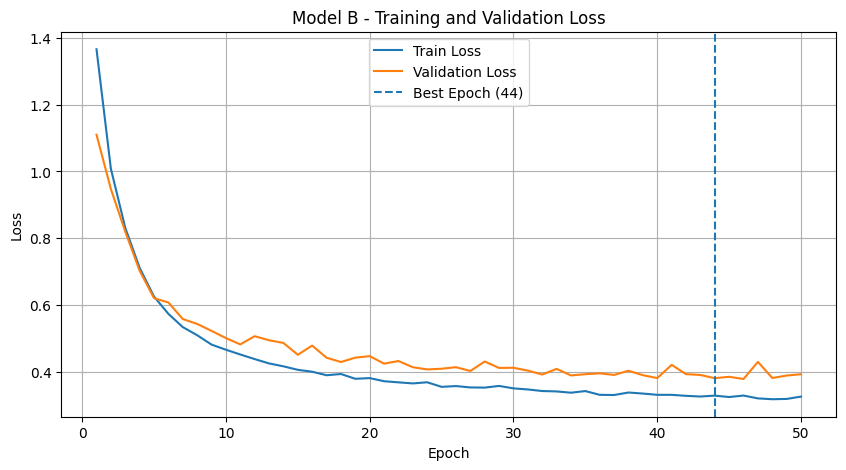

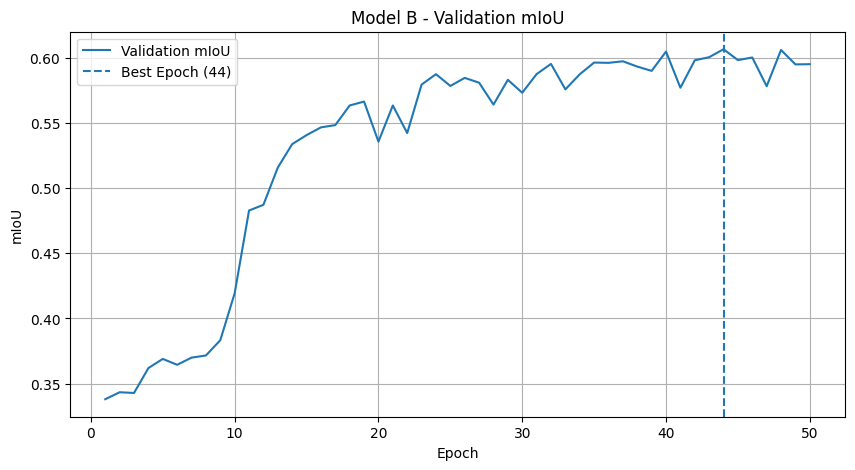

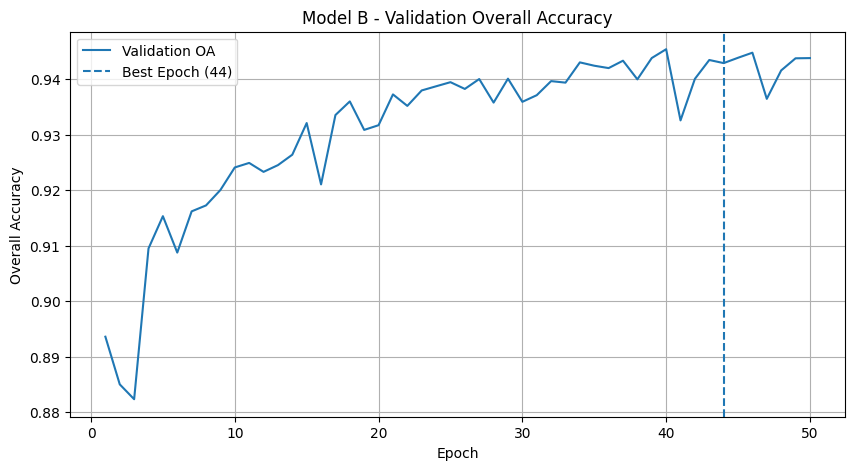

Grafice salvate în: /content/drive/MyDrive/NN/results_B


In [ ]:
import matplotlib.pyplot as plt

# 1. Train Loss vs Validation Loss
plt.figure(figsize=(10, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train Loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation Loss")
plt.axvline(44, linestyle="--", label="Best Epoch (44)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model B - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.savefig(OUTPUT_ROOT / "loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Validation mIoU
plt.figure(figsize=(10, 5))
plt.plot(history_df["epoch"], history_df["val_miou"], label="Validation mIoU")
plt.axvline(44, linestyle="--", label="Best Epoch (44)")
plt.xlabel("Epoch")
plt.ylabel("mIoU")
plt.title("Model B - Validation mIoU")
plt.legend()
plt.grid(True)
plt.savefig(OUTPUT_ROOT / "miou_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Validation OA
plt.figure(figsize=(10, 5))
plt.plot(history_df["epoch"], history_df["val_oa"], label="Validation OA")
plt.axvline(44, linestyle="--", label="Best Epoch (44)")
plt.xlabel("Epoch")
plt.ylabel("Overall Accuracy")
plt.title("Model B - Validation Overall Accuracy")
plt.legend()
plt.grid(True)
plt.savefig(OUTPUT_ROOT / "oa_curve.png", dpi=300, bbox_inches="tight")
plt.show()

print("Grafice salvate în:", OUTPUT_ROOT)

Calculare matrice de confuzie:   0%|          | 0/878 [00:00<?, ?it/s]

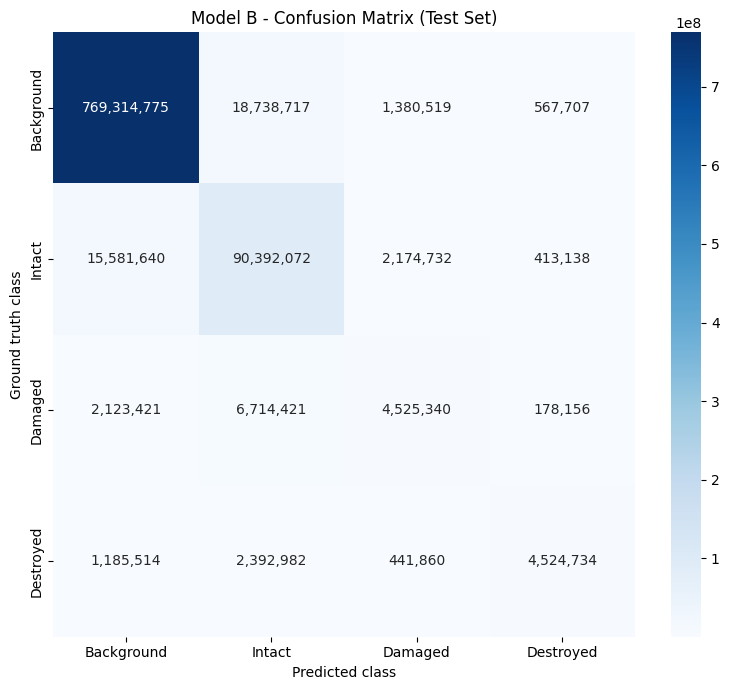

Matricea de confuzie a fost salvată!
Locație: /content/drive/MyDrive/NN/results_B/confusion_matrix.png


In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# Inițializăm matricea de confuzie
num_classes = 4
confusion_matrix = np.zeros(
    (num_classes, num_classes),
    dtype=np.int64
)

model.eval()

with torch.no_grad():
    for optical, sar, target, names in tqdm(
        test_loader,
        desc="Calculare matrice de confuzie"
    ):
        optical = optical.to(device)
        sar = sar.to(device)
        target = target.to(device)

        logits = predict_tiled(model, optical, sar)
        predictions = logits.argmax(dim=1)

        valid = target != IGNORE_INDEX

        target_valid = target[valid].cpu().numpy()
        pred_valid = predictions[valid].cpu().numpy()

        indices = num_classes * target_valid + pred_valid

        confusion_matrix += np.bincount(
            indices,
            minlength=num_classes ** 2
        ).reshape(num_classes, num_classes)

# Afișare
class_names = ["Background", "Intact", "Damaged", "Destroyed"]

plt.figure(figsize=(8, 7))
sns.heatmap(
    confusion_matrix,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted class")
plt.ylabel("Ground truth class")
plt.title("Model B - Confusion Matrix (Test Set)")
plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Salvare valori brute
np.save(
    OUTPUT_ROOT / "confusion_matrix.npy",
    confusion_matrix
)

print("Matricea de confuzie a fost salvată!")
print("Locație:", OUTPUT_ROOT / "confusion_matrix.png")

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import imageio.v2 as imageio
from tqdm.auto import tqdm

VIS_DIR = OUTPUT_ROOT / "visual_predictions"
VIS_DIR.mkdir(parents=True, exist_ok=True)

CLASS_COLORS = np.array([
    [0, 0, 0],       # Background - negru
    [0, 180, 0],     # Intact - verde
    [255, 200, 0],   # Damaged - galben
    [220, 0, 0],     # Destroyed - roșu
    [255, 255, 255]  # Ignore - alb
], dtype=np.uint8)

def colorize_mask(mask):
    mask = mask.astype(np.uint8)
    mask = np.where(mask == 255, 4, mask)
    return CLASS_COLORS[mask]

# Selectăm primele 5 imagini din test
selected_names = split_names["test"][:5]

for name in tqdm(selected_names, desc="Generating visual predictions"):

    optical = imageio.imread(
        DATASET_ROOT / "pre-event" / f"{name}_pre_disaster.tif"
    )[..., :3]

    sar = imageio.imread(
        DATASET_ROOT / "post-event" / f"{name}_post_disaster.tif"
    )

    target = imageio.imread(
        DATASET_ROOT / "target" / f"{name}_building_damage.tif"
    )

    # Pregătim imaginile pentru model
    optical_tensor = torch.from_numpy(
        optical.astype(np.float32)
    ).permute(2, 0, 1)

    optical_tensor = (
        optical_tensor - torch.tensor(OPTICAL_MEAN).view(3, 1, 1)
    ) / torch.tensor(OPTICAL_STD).view(3, 1, 1)

    if sar.ndim == 2:
        sar = sar[..., None]

    sar_tensor = torch.from_numpy(
        sar.astype(np.float32)
    ).permute(2, 0, 1)

    sar_tensor = (
        sar_tensor - SAR_MEAN
    ) / SAR_STD

    optical_tensor = optical_tensor.unsqueeze(0).to(device)
    sar_tensor = sar_tensor.unsqueeze(0).to(device)

    # Segmentare semantică
    with torch.no_grad():
        logits = predict_tiled(model, optical_tensor, sar_tensor)
        prediction = logits.argmax(dim=1)[0].cpu().numpy()

    # Măști colorate
    gt_color = colorize_mask(target)
    pred_color = colorize_mask(prediction)

    # Figura comparativă
    fig, axes = plt.subplots(1, 4, figsize=(20, 6))

    axes[0].imshow(optical)
    axes[0].set_title("Optical")

    axes[1].imshow(sar.squeeze(), cmap="gray")
    axes[1].set_title("SAR")

    axes[2].imshow(gt_color)
    axes[2].set_title("Ground Truth")

    axes[3].imshow(pred_color)
    axes[3].set_title("Model B Prediction")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(f"Semantic Segmentation - {name}")
    plt.tight_layout()

    fig.savefig(
        VIS_DIR / f"{name}_comparison.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.close(fig)

    # Salvăm și masca numerică
    np.save(VIS_DIR / f"{name}_prediction.npy", prediction)

print("\nPredicțiile vizuale au fost salvate în:", VIS_DIR)
print("Număr imagini procesate:", len(selected_names))

Generating visual predictions:   0%|          | 0/5 [00:00<?, ?it/s]


Predicțiile vizuale au fost salvate în: /content/drive/MyDrive/NN/results_B/visual_predictions
Număr imagini procesate: 5


In [ ]:
import imageio.v2 as imageio
import numpy as np

interesting_images = []

for name in split_names["test"]:
    target_img = imageio.imread(
        DATASET_ROOT / "target" / f"{name}_building_damage.tif"
    )

    classes = np.unique(target_img)

    if 2 in classes and 3 in classes:
        interesting_images.append(name)

print("Imagini cu Damaged și Destroyed:", len(interesting_images))
print("\nPrimele 10 imagini:")
for name in interesting_images[:10]:
    print(name)

Imagini cu Damaged și Destroyed: 137

Primele 10 imagini:
bata-explosion_00000062
bata-explosion_00000074
bata-explosion_00000049
beirut-explosion_00000030
beirut-explosion_00000003
haiti-earthquake_00000060
hawaii-wildfire_00000003
hawaii-wildfire_00000046
hawaii-wildfire_00000014
hawaii-wildfire_00000041


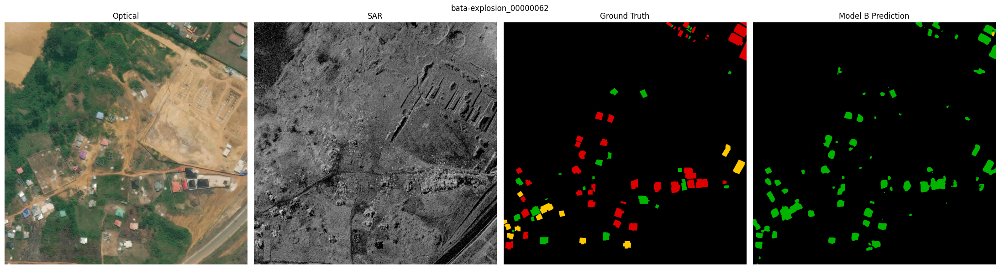

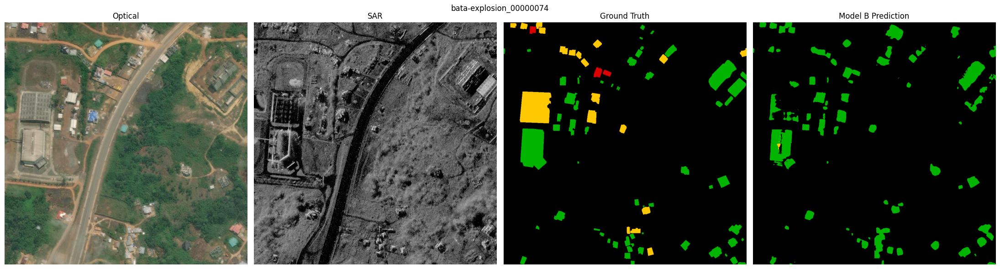

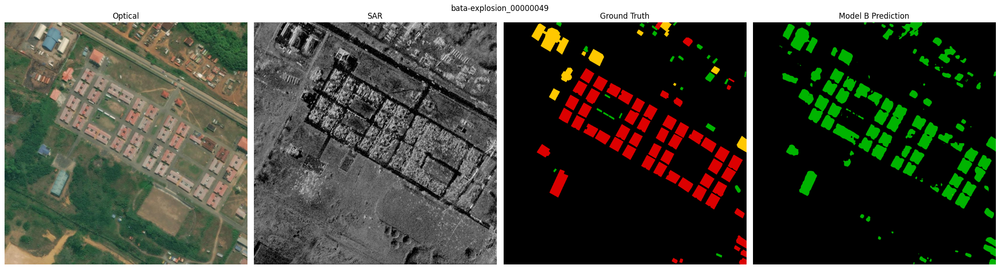

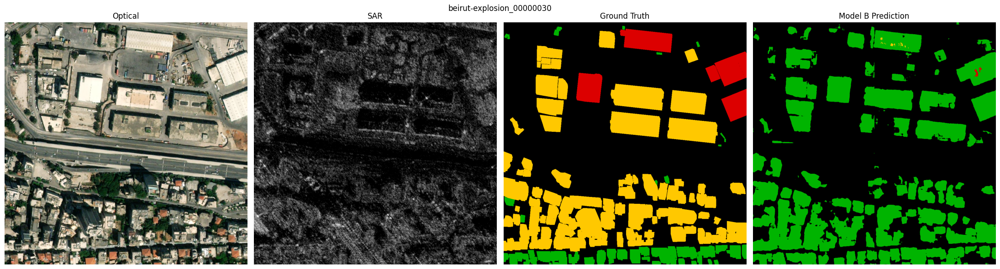

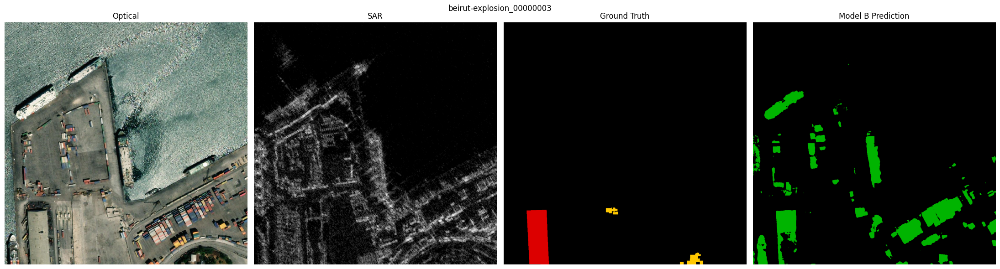

Segmentări salvate în: /content/drive/MyDrive/NN/results_B/visual_predictions_damage
Număr imagini: 5


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import imageio.v2 as imageio
import torch

VIS_DAMAGE_DIR = OUTPUT_ROOT / "visual_predictions_damage"
VIS_DAMAGE_DIR.mkdir(parents=True, exist_ok=True)

selected_names = interesting_images[:5]

for name in selected_names:

    optical = imageio.imread(
        DATASET_ROOT / "pre-event" / f"{name}_pre_disaster.tif"
    )[..., :3]

    sar = imageio.imread(
        DATASET_ROOT / "post-event" / f"{name}_post_disaster.tif"
    )

    target = imageio.imread(
        DATASET_ROOT / "target" / f"{name}_building_damage.tif"
    )

    # Normalizare Optical
    optical_tensor = torch.from_numpy(
        optical.astype(np.float32)
    ).permute(2, 0, 1)

    optical_tensor = (
        optical_tensor - torch.tensor(OPTICAL_MEAN).view(3, 1, 1)
    ) / torch.tensor(OPTICAL_STD).view(3, 1, 1)

    # Normalizare SAR
    if sar.ndim == 2:
        sar = sar[..., None]

    sar_tensor = torch.from_numpy(
        sar.astype(np.float32)
    ).permute(2, 0, 1)

    sar_tensor = (sar_tensor - SAR_MEAN) / SAR_STD

    optical_tensor = optical_tensor.unsqueeze(0).to(device)
    sar_tensor = sar_tensor.unsqueeze(0).to(device)

    # Predicție
    with torch.no_grad():
        logits = predict_tiled(model, optical_tensor, sar_tensor)
        prediction = logits.argmax(dim=1)[0].cpu().numpy()

    # Vizualizare
    fig, axes = plt.subplots(1, 4, figsize=(22, 6))

    axes[0].imshow(optical)
    axes[0].set_title("Optical")

    axes[1].imshow(sar.squeeze(), cmap="gray")
    axes[1].set_title("SAR")

    axes[2].imshow(colorize_mask(target))
    axes[2].set_title("Ground Truth")

    axes[3].imshow(colorize_mask(prediction))
    axes[3].set_title("Model B Prediction")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(name)
    plt.tight_layout()

    fig.savefig(
        VIS_DAMAGE_DIR / f"{name}_comparison.png",
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    np.save(
        VIS_DAMAGE_DIR / f"{name}_prediction.npy",
        prediction
    )

print("Segmentări salvate în:", VIS_DAMAGE_DIR)
print("Număr imagini:", len(selected_names))

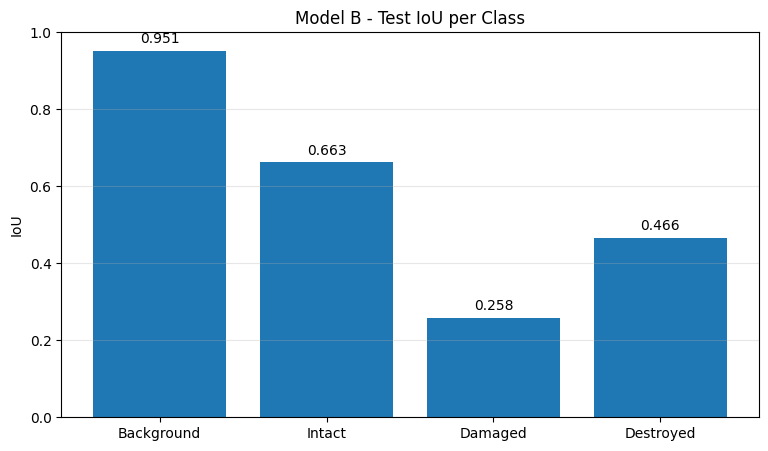

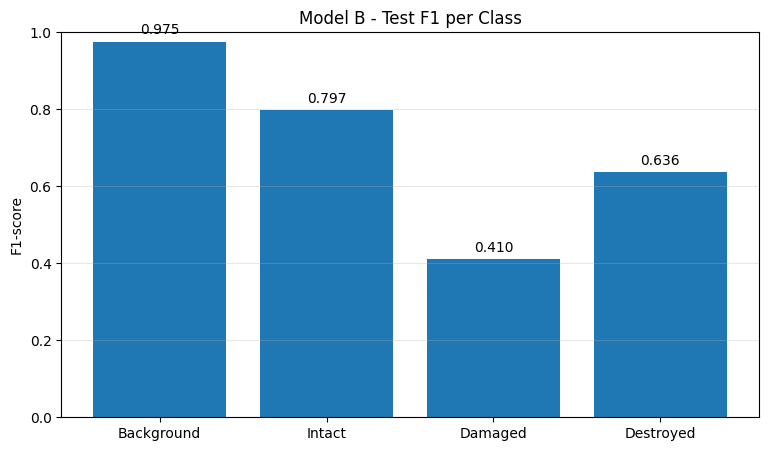

Graficele au fost salvate!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

class_names = ["Background", "Intact", "Damaged", "Destroyed"]

iou_values = [
    test_results["iou_per_class"][i]
    for i in range(4)
]

f1_values = [
    test_results["f1_per_class"][i]
    for i in range(4)
]

# IoU per class
plt.figure(figsize=(9, 5))
bars = plt.bar(class_names, iou_values)

plt.ylim(0, 1)
plt.ylabel("IoU")
plt.title("Model B - Test IoU per Class")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, iou_values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.savefig(OUTPUT_ROOT / "test_iou_per_class.png",
            dpi=300, bbox_inches="tight")
plt.show()

# F1 per class
plt.figure(figsize=(9, 5))
bars = plt.bar(class_names, f1_values)

plt.ylim(0, 1)
plt.ylabel("F1-score")
plt.title("Model B - Test F1 per Class")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, f1_values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.savefig(OUTPUT_ROOT / "test_f1_per_class.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Graficele au fost salvate!")

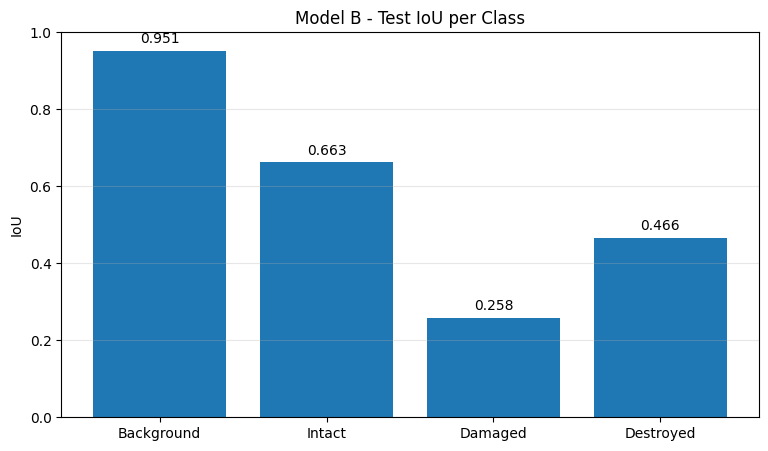

In [ ]:
plt.figure(figsize=(9, 5))

iou_values = test_results["iou_per_class"]
class_names = ["Background", "Intact", "Damaged", "Destroyed"]

bars = plt.bar(class_names, iou_values)

plt.ylim(0, 1)
plt.ylabel("IoU")
plt.title("Model B - Test IoU per Class")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, iou_values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.savefig(
    OUTPUT_ROOT / "test_iou_per_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

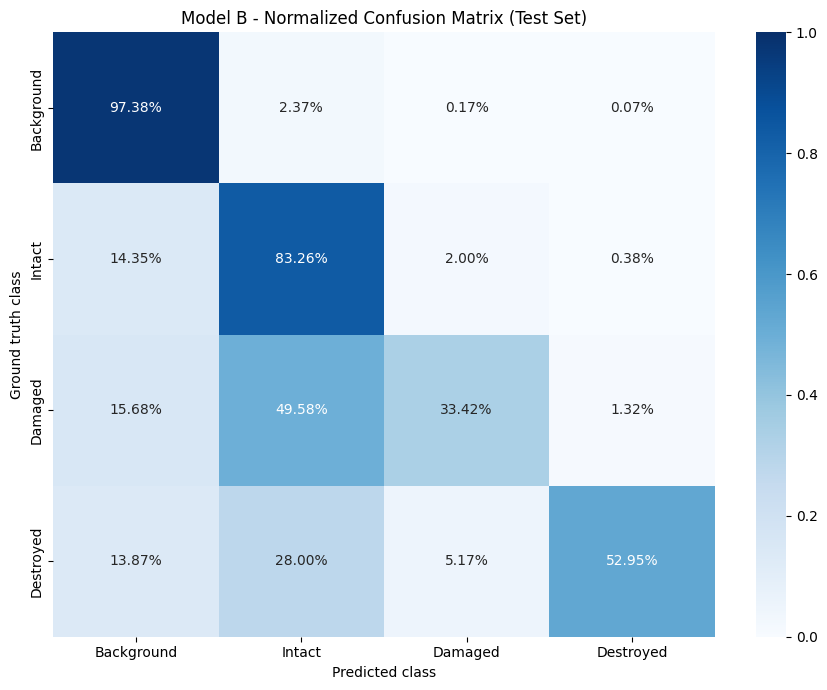

Matricea normalizată a fost salvată!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

class_names = ["Background", "Intact", "Damaged", "Destroyed"]

# Normalizare pe rânduri (fiecare clasă reală)
cm_normalized = confusion_matrix.astype(float) / np.maximum(
    confusion_matrix.sum(axis=1, keepdims=True), 1
)

# Grafic
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2%",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1
)

plt.xlabel("Predicted class")
plt.ylabel("Ground truth class")
plt.title("Model B - Normalized Confusion Matrix (Test Set)")
plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT / "confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Salvăm și valorile numerice
pd.DataFrame(
    cm_normalized,
    index=class_names,
    columns=class_names
).to_csv(OUTPUT_ROOT / "confusion_matrix_normalized.csv")

print("Matricea normalizată a fost salvată!")

Dimensiune: (1024, 1024)
Tip date: uint8
Valori unice: (array([0, 1, 2, 3], dtype=uint8), array([658974,  52047, 283422,  54133]))


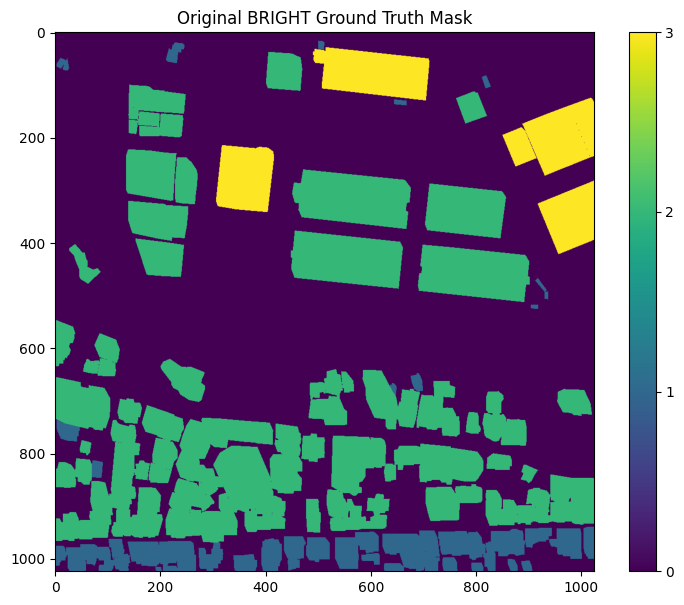

In [ ]:
import imageio.v2 as imageio
import numpy as np
import matplotlib.pyplot as plt

name = "beirut-explosion_00000030"

mask_path = (
    DATASET_ROOT / "target" /
    f"{name}_building_damage.tif"
)

mask = imageio.imread(mask_path)

print("Dimensiune:", mask.shape)
print("Tip date:", mask.dtype)
print("Valori unice:", np.unique(mask, return_counts=True))

plt.figure(figsize=(9, 7))
plt.imshow(mask, cmap="viridis", vmin=0, vmax=3)
plt.colorbar(ticks=[0, 1, 2, 3, 255])
plt.title("Original BRIGHT Ground Truth Mask")
plt.show()

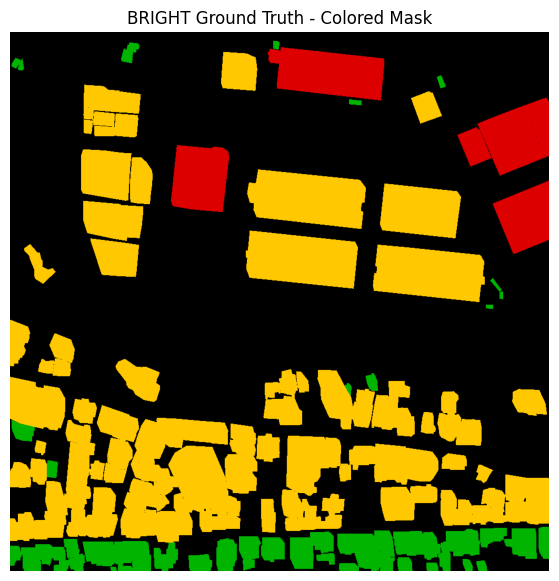

In [ ]:
plt.figure(figsize=(9, 7))
plt.imshow(colorize_mask(mask))
plt.title("BRIGHT Ground Truth - Colored Mask")
plt.axis("off")
plt.show()

# Evaluation

# Results